# Импорты библиотек

In [56]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from collections import Counter
import re
from sklearn.decomposition import PCA
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
from scipy.stats import pearsonr

---

In [2]:
train_df = pd.read_csv('data/train_data.csv')
train_df.head()

,Id,Title,Description,Download_link,ECR
0,5902367b4d7d4c38fe4638593ddea7ee,zanzibarisland zanzibarbeach zanzibarlifest...,NaN,https://cf-st.sc-cdn.net/d/Pi2xtXMNjx6GfVEJnmo...,0.0
1,9be2d4d5e8d4bfd1f5ce59f51d7d96dd,NaN,NaN,https://cf-st.sc-cdn.net/d/p8788TQnO5KF94SH8Uz...,0.0
2,1e9b26ba367a8ed559916599294bbfc1,NaN,skullskullskullskullHAHAHA,https://cf-st.sc-cdn.net/d/7xbgKKhZWSVFpOnIAmN...,0.0
3,20c0ea87f1d3d7ce1f5480a8d748e48e,NaN,NaN,https://bolt-gcdn.sc-cdn.net/y/OWVh8dymJFW6fVo...,0.0
4,bf58c43be3a6c500eae6cb599b0f8935,NaN,NaN,https://cf-st.sc-cdn.net/h/Nwt7Zfg7rE31iGoJmMV...,0.0


In [3]:
train_df.shape

(106192, 5)

## ECR
---

**ECR (Engagement Continuation Rate)** в датасете SnapUGC - это ключевая метрика, которая показывает, насколько видео способно заинтересовать зрителя в первые секунды. Она напрямую отвечает на вопрос: «Какая доля зрителей осталась смотреть видео дольше 5 секунд».

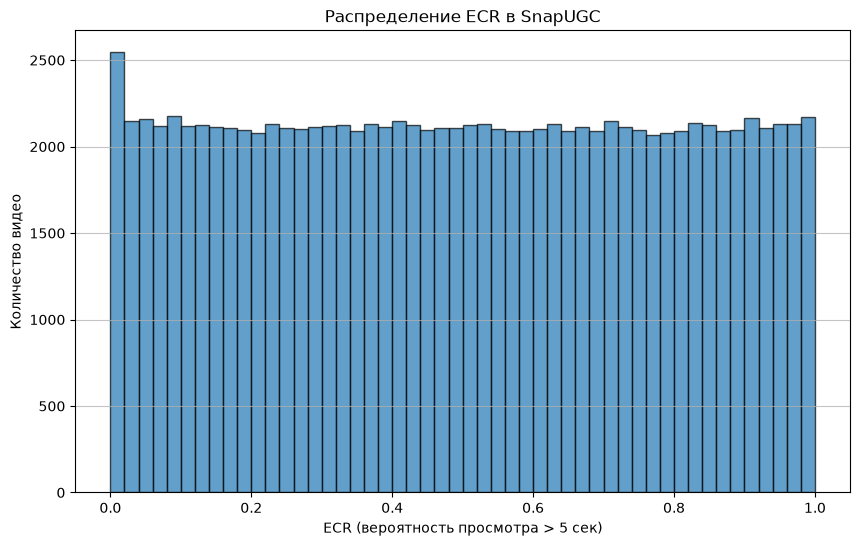

count    106192.000000
mean          0.497539
std           0.290418
min           0.000000
25%           0.245766
50%           0.497081
75%           0.748484
max           0.999992
Name: ECR, dtype: float64

In [4]:
import pandas as pd

plt.figure(figsize=(10, 6))
plt.hist(train_df['ECR'].dropna(), bins=50, edgecolor='black', alpha=0.7)
plt.title('Распределение ECR в SnapUGC')
plt.xlabel('ECR (вероятность просмотра > 5 сек)')
plt.ylabel('Количество видео')
plt.grid(axis='y', alpha=0.75)
plt.show()

display(train_df['ECR'].describe())

По графику видно что целевая переменная ECR имеет **равномерное распределение**. Скорее всего авторы датасета сбалансировали выборку.

## Music
---

Добавляем в датасет извлеченный признак **Music** - содержат результаты классификации звука (топ вероятных звуков/категорий)

In [5]:
MUSIC_DIR = 'data/Music' 

def read_music_text(video_id):
    file_path = os.path.join(MUSIC_DIR, f"{video_id}.txt")
    
    if os.path.exists(file_path):
        with open(file_path, 'r', encoding='utf-8') as f:
            content = f.read().strip()
            return content
    else:
        return None 
        
train_df['music'] = train_df['Id'].apply(read_music_text)

print(f"Всего строк в датасете: {len(train_df)}")
print(f"Успешно добавлено музыкальных признаков: {train_df['music'].notna().sum()}")
print(f"Пропущено (файл не найден): {train_df['music'].isna().sum()}")

train_df.to_csv('train_data_with_music.csv', index=False)

Всего строк в датасете: 106192
Успешно добавлено музыкальных признаков: 106192
Пропущено (файл не найден): 0


In [6]:
train_df.head()

,Id,Title,Description,Download_link,ECR,music
0,5902367b4d7d4c38fe4638593ddea7ee,zanzibarisland zanzibarbeach zanzibarlifest...,NaN,https://cf-st.sc-cdn.net/d/Pi2xtXMNjx6GfVEJnmo...,0.0,"Music, Rhythm and blues, Music of Africa, Afro..."
1,9be2d4d5e8d4bfd1f5ce59f51d7d96dd,NaN,NaN,https://cf-st.sc-cdn.net/d/p8788TQnO5KF94SH8Uz...,0.0,"Speech, Music, Inside, small room, Narration, ..."
2,1e9b26ba367a8ed559916599294bbfc1,NaN,skullskullskullskullHAHAHA,https://cf-st.sc-cdn.net/d/7xbgKKhZWSVFpOnIAmN...,0.0,"Speech, Child speech, kid speaking, Inside, sm..."
3,20c0ea87f1d3d7ce1f5480a8d748e48e,NaN,NaN,https://bolt-gcdn.sc-cdn.net/y/OWVh8dymJFW6fVo...,0.0,"Silence, Sound effect, Outside, rural or natur..."
4,bf58c43be3a6c500eae6cb599b0f8935,NaN,NaN,https://cf-st.sc-cdn.net/h/Nwt7Zfg7rE31iGoJmMV...,0.0,"Speech, Narration, monologue, Inside, small ro..."


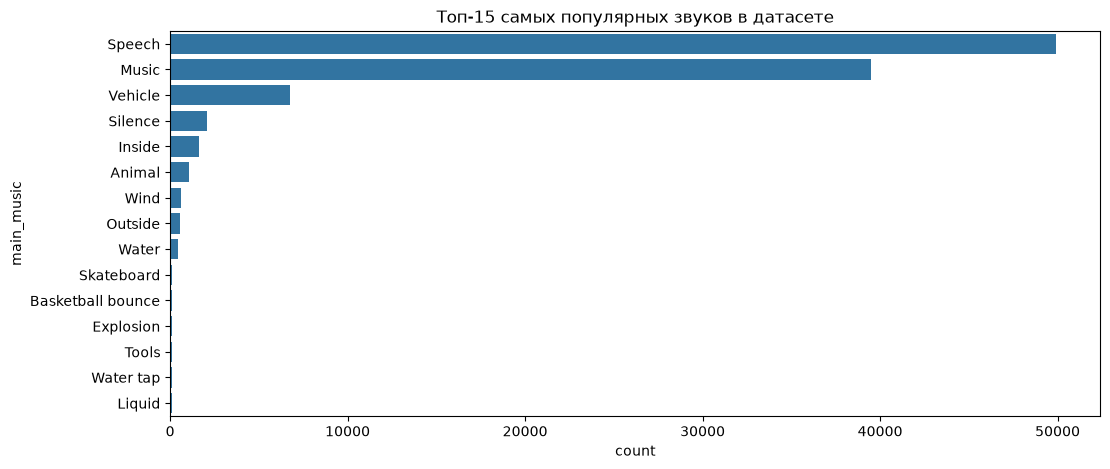

In [93]:
def parse_music(text):
    if pd.isna(text):
        return 'Unknown', 0
    try:
        genres = ast.literal_eval(text) 
        if isinstance(genres, list) and len(genres) > 0:
            main_genre = genres[0] 
            num_genres = len(set(genres)) 
            return main_genre, num_genres
    except:
        parts = text.replace("'", "").replace("[", "").replace("]", "").split(',')
        main_genre = parts[0].strip()
        return main_genre, len(parts)
    return 'Unknown', 0

train_df[['main_music', 'num_genres']] = train_df['music'].apply(
    lambda x: pd.Series(parse_music(x))
)

plt.figure(figsize=(12, 5))
sns.countplot(data=train_df, y='main_music', order=train_df['main_music'].value_counts().index[:15])
plt.title('Топ-15 самых популярных звуков в датасете')
plt.show()

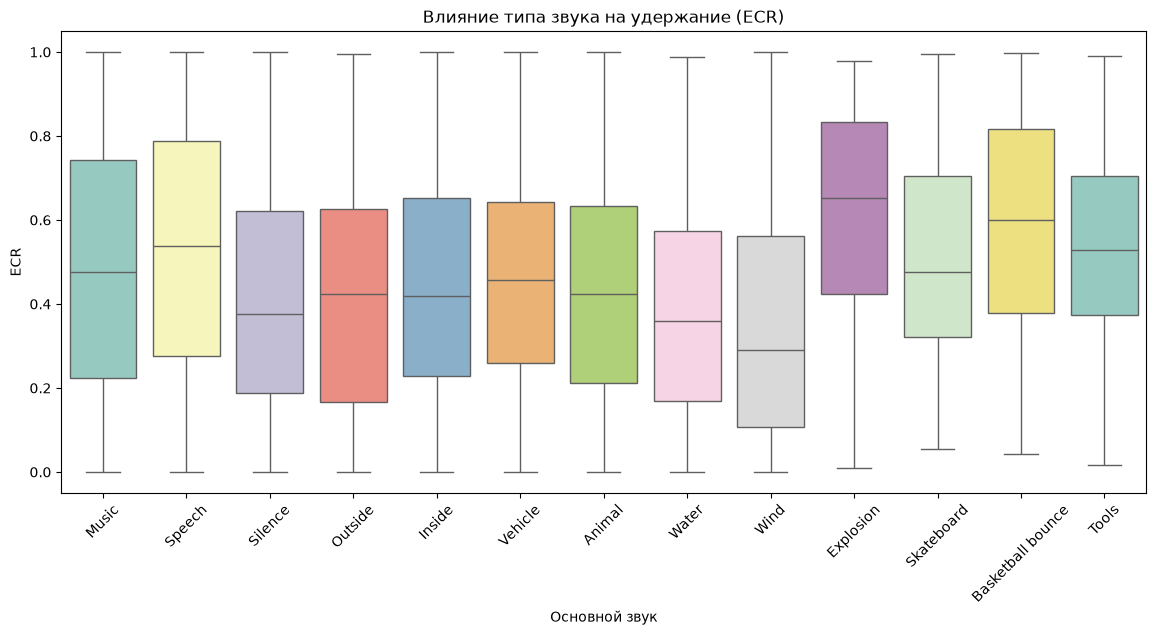

In [91]:
top_genres = train_df['main_music'].value_counts()[train_df['main_music'].value_counts() > 100].index
df_filtered = train_df[train_df['main_music'].isin(top_genres)]

plt.figure(figsize=(14, 6))
sns.boxplot(data=df_filtered, x='main_music', y='ECR', palette='Set3', hue='main_music')
plt.xticks(rotation=45)
plt.title('Влияние типа звука на удержание (ECR)')
plt.ylabel('ECR')
plt.xlabel('Основной звук')
plt.show()

По графику видно, что звук коррелирует с ECR. Так на графике можно выделить звуки, которые характеризуют более высокий медианный ECR и звуки у которых медианный ECR гораздо ниже.

*Высокий ECR*:
 - Explosion (Взрыв) - ~ медиана 0.65 ECR
 - Basketball bounce (Отскок баскетбольного мяча) - медиана ~0.6 ECR
 - Speech (Речь) - медиана ~0.55 ECR, но с большим разбросом
   
*Низкий ECR*:
 - Wind (Ветер) - медиана ~0.25 ECR
 - Silence (Ветер) - медиана ~0.3 ECR

Видео с "взрывами" и "баскетбольным мячом" - это, скорее всего, короткие, динамичные, экшен-ролики или спортивные моменты с резким звуком. Резкий, громкий звук в первые секунды может привлечь внимание.

"Тишина" (Silence) или "Ветер" (Wind)- это скучные, фоновые видео без четкого аудио-стимула. Люди свайпают их моментально, отсюда низкий ECR.

"Речь" (Speech) - это видеоблоги, туториалы или разговорные ролики. Если человек интересно говорит, его досматривают, а если нет то свайпают. Отсюда такой огромный разброс (высокий ящик).

**Вывод:** Наличие резких, динамичных звуков (взрыв, удар мяча) или активной речи коррелирует с более высоким ECR. Фоновые звуки (ветер, вода, звук машин) или тишина - снижают удержание.

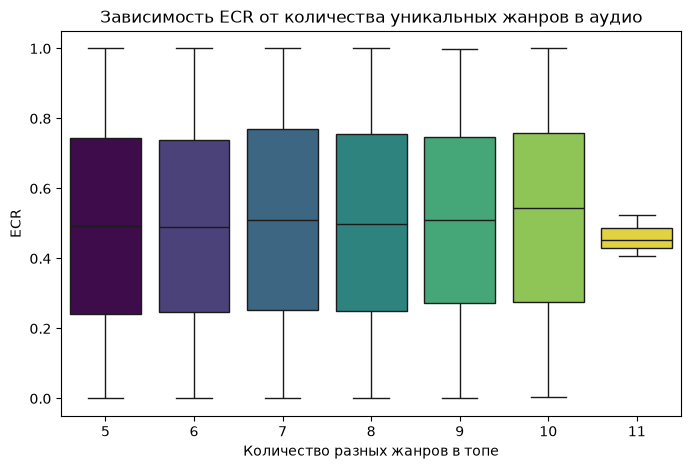

In [9]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=train_df, x='num_genres', y='ECR', palette='viridis', hue='num_genres', legend=False)
plt.title('Зависимость ECR от количества уникальных жанров в аудио')
plt.xlabel('Количество разных жанров в топе')
plt.ylabel('ECR')
plt.show()

Кол-во звуков не показало сильной зависимотси с ECR

### **Вывод**: В ходе анализа аудиопризнаков (Music) было установлено, что тип звука влияет на удержание. Видео, содержащие резкие и динамичные звуки (взрывы, удары), а также активную речь, имеют статистически более высокий медианный ECR по сравнению с видео, где преобладает фоновый шум или тишина. Количество уникальных звуков в топ-5 не показало сильной линейной зависимости с целевой переменной.

## Caption
---

в папке Caption, авторы датасета предоставили текстовые описания видео (сгенерированные нейросетью), и векторные представления (эмбеддинги) этих описаний.

In [10]:
CAPTION_DIR = 'data/Caption' 

def read_caption(video_id):
    path = os.path.join(CAPTION_DIR, f"{video_id}.txt")
    if os.path.exists(path):
        with open(path, 'r', encoding='utf-8') as f:
            return f.read().strip()
    return ""

train_df['caption_text'] = train_df['Id'].apply(read_caption)

print(f"Всего строк в датасете: {len(train_df)}")
print(f"Успешно добавлено признаков: {train_df['caption_text'].notna().sum()}")
print(f"Пропущено (файл не найден): {train_df['caption_text'].isna().sum()}")

Всего строк в датасете: 106192
Успешно добавлено признаков: 106192
Пропущено (файл не найден): 0


In [11]:
train_df.head()

,Id,Title,Description,Download_link,ECR,music,main_music,num_genres,caption_text
0,5902367b4d7d4c38fe4638593ddea7ee,zanzibarisland zanzibarbeach zanzibarlifest...,NaN,https://cf-st.sc-cdn.net/d/Pi2xtXMNjx6GfVEJnmo...,0.0,"Music, Rhythm and blues, Music of Africa, Afro...",Music,5,a group of people are jumping into the water
1,9be2d4d5e8d4bfd1f5ce59f51d7d96dd,NaN,NaN,https://cf-st.sc-cdn.net/d/p8788TQnO5KF94SH8Uz...,0.0,"Speech, Music, Inside, small room, Narration, ...",Speech,7,a boy is talking
2,1e9b26ba367a8ed559916599294bbfc1,NaN,skullskullskullskullHAHAHA,https://cf-st.sc-cdn.net/d/7xbgKKhZWSVFpOnIAmN...,0.0,"Speech, Child speech, kid speaking, Inside, sm...",Speech,7,a boy and a girl are talking
3,20c0ea87f1d3d7ce1f5480a8d748e48e,NaN,NaN,https://bolt-gcdn.sc-cdn.net/y/OWVh8dymJFW6fVo...,0.0,"Silence, Sound effect, Outside, rural or natur...",Silence,7,a group of people are looking at different typ...
4,bf58c43be3a6c500eae6cb599b0f8935,NaN,NaN,https://cf-st.sc-cdn.net/h/Nwt7Zfg7rE31iGoJmMV...,0.0,"Speech, Narration, monologue, Inside, small ro...",Speech,8,a man is counting money


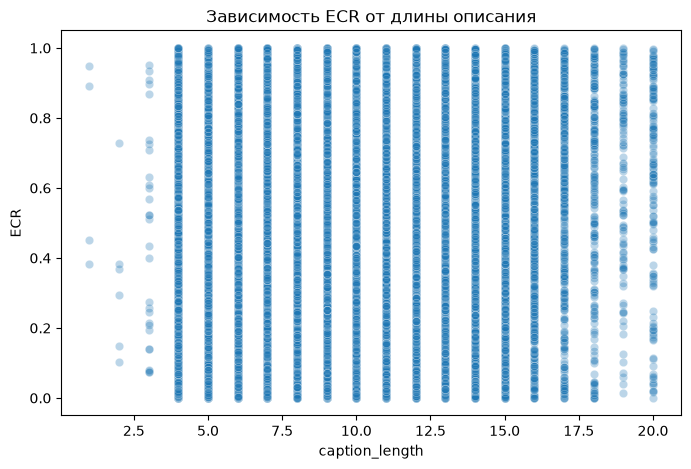

In [12]:
train_df['caption_length'] = train_df['caption_text'].apply(lambda x: len(x.split()))

plt.figure(figsize=(8, 5))
sns.scatterplot(data=train_df, x='caption_length', y='ECR', alpha=0.3)
plt.title('Зависимость ECR от длины описания')
plt.show()

Явной зависимости от длины описание нет

Выбранные слова для анализа: ['man', 'woman', 'talking', 'person', 'sitting', 'group', 'car', 'playing', 'people', 'standing', 'girl', 'front', 'walking', 'shirt', 'camera']

Влияние слов на ECR (отсортировано по силе эффекта):


,word,count,ECR_with,ECR_without,Difference
0,man,41185,0.596408,0.430961,0.165447
2,talking,13219,0.602630,0.484923,0.117707
13,shirt,4475,0.601604,0.493266,0.108339
7,playing,7381,0.571912,0.492381,0.079530
9,standing,6314,0.536513,0.494436,0.042078
11,front,4816,0.475093,0.497957,-0.022864
10,girl,5100,0.474854,0.498043,-0.023189
14,camera,4347,0.473363,0.497805,-0.024441
3,person,12818,0.467861,0.501287,-0.033426
4,sitting,8048,0.463627,0.499636,-0.036009


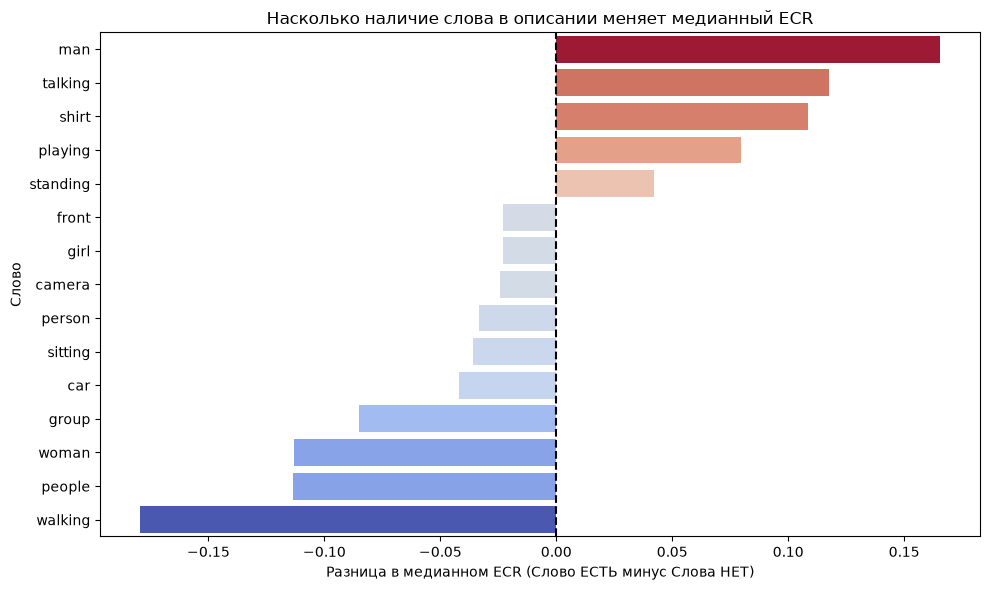

In [13]:
all_text = ' '.join(train_df['caption_text'].dropna().astype(str)).lower()
words = re.findall(r'\b[a-z]{3,}\b', all_text) 

word_counts = Counter(words)
top_20_words = [word for word, count in word_counts.most_common(20)]

stop_words = {'the', 'and', 'with', 'this', 'that', 'from', 'are', 'for', 'has', 'video', 'a', 'in', 'of', 'to', 'is', 'on'}
top_20_words = [w for w in top_20_words if w not in stop_words][:15]

print("Выбранные слова для анализа:", top_20_words)

for word in top_20_words:
    train_df[f'has_{word}'] = train_df['caption_text'].astype(str).str.lower().str.contains(rf'\b{word}\b', regex=True).astype(int)

results = []
for word in top_20_words:
    col_name = f'has_{word}'

    ecr_with = train_df[train_df[col_name] == 1]['ECR'].median()
    ecr_without = train_df[train_df[col_name] == 0]['ECR'].median()

    diff = ecr_with - ecr_without
    
    results.append({
        'word': word,
        'count': train_df[col_name].sum(),
        'ECR_with': ecr_with,
        'ECR_without': ecr_without,
        'Difference': diff
    })

results_df = pd.DataFrame(results).sort_values(by='Difference', ascending=False)

print("\nВлияние слов на ECR (отсортировано по силе эффекта):")
display(results_df)

plt.figure(figsize=(10, 6))
sns.barplot(data=results_df, x='Difference', y='word', palette='coolwarm', hue='Difference', legend=False)
plt.axvline(0, color='black', linestyle='--') 
plt.title('Насколько наличие слова в описании меняет медианный ECR')
plt.xlabel('Разница в медианном ECR (Слово ЕСТЬ минус Слова НЕТ)')
plt.ylabel('Слово')
plt.tight_layout()
plt.show()

Видно по графику и таблице что среди 20 самых популярных слов есть слова которые оказывают влияние на медианный ECR. 

Так например у видео где в описании есть слово *'man'* медианный ECR увеличиавается на **16.5** п.п. (ECR_with: 0.596, ECR_without: 0.43) или где в описании есть слово *'walking'* мкдианный ECR уменьшается на **17.9** п.п. (ECR_with: 0.325, ECR_without: 0.5)

**Вывод**: Видео, в описании которых присутствуют слова, обозначающие активное взаимодействие человека с камерой (talking, playing), а также конкретные объекты (shirt), имеют более высокий медианный ECR (+10–16%). В то же время, описания, содержащие статичные сцены или фоновое передвижение (walking, group, people), снижают удержание (-10–15%). Это позволяет сделать вывод, что для повышения вовлеченности контент должен содержать четкий сюжет или активного персонажа, а не быть фоновым

Успешно загружено и усреднено: 10000 видео
Итоговая матрица признаков: (10000, 1024)


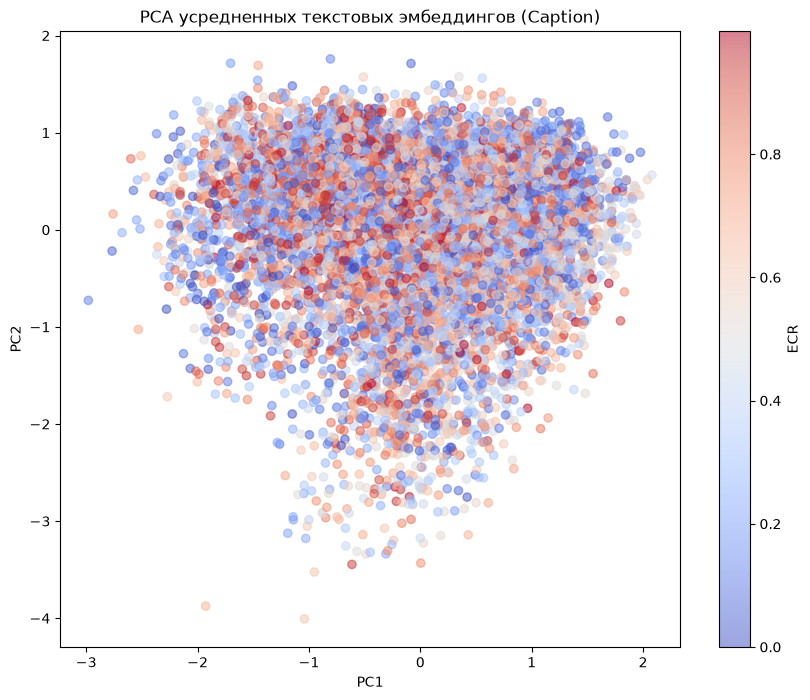

In [32]:
NPY_DIR = 'data/Caption' 

def load_and_aggregate_npy(video_id):
    path = os.path.join(NPY_DIR, f"{video_id}.npy")
    if not os.path.exists(path):
        return None
    try:
        vec = np.load(path)
        vec = vec.squeeze(0) 
        if vec.ndim == 2:
            aggregated_vec = np.mean(vec, axis=0)
        else:
            aggregated_vec = vec.flatten()
            
        return aggregated_vec
    except Exception as e:
        print(f"Ошибка при загрузке {video_id}: {e}")
        return None

train_df['ecr_bin'] = pd.qcut(train_df['ECR'], q=10, labels=False)

sample_df, _ = train_test_split(
    train_df, 
    train_size=10000, 
    stratify=train_df['ecr_bin'], 
    random_state=42
)

sample_df['npy_vector'] = sample_df['Id'].apply(load_and_aggregate_npy)

valid_df = sample_df.dropna(subset=['npy_vector']).copy()
print(f"Успешно загружено и усреднено: {len(valid_df)} видео")

if len(valid_df) > 0:
    X = np.stack(valid_df['npy_vector'].values)
    print(f"Итоговая матрица признаков: {X.shape}")

    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X)

    plt.figure(figsize=(10, 8))
    scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=valid_df['ECR'], cmap='coolwarm', alpha=0.5)
    plt.colorbar(scatter, label='ECR')
    plt.title('PCA усредненных текстовых эмбеддингов (Caption)')
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.show()
else:
    print("Нет данных для построения графика.")

По облаку точек видно что линенйое разделение по тексту невозможно (линейное потому что PCA). Точки образуют плотное облако неразделимое на кластеры по цветам.

**Вывод**: текстовая модальность сама по себе не содержит четкого линейного сигнала для предсказания удержания. Для извлечения полезной информации из текста потребуются нелинейные модели (например, градиентный бустинг или нейронные сети), либо комбинирование текстовых признаков с визуальными и аудио-характеристиками

### Caption + Music
---

Статистика ECR по комбинациям признаков:
                 count   mean  median
combo                                
1. Text + Audio   8486  0.565   0.617
2. Text only      4733  0.544   0.578
3. Audio only    41415  0.518   0.525
4. Neither       51558  0.466   0.452


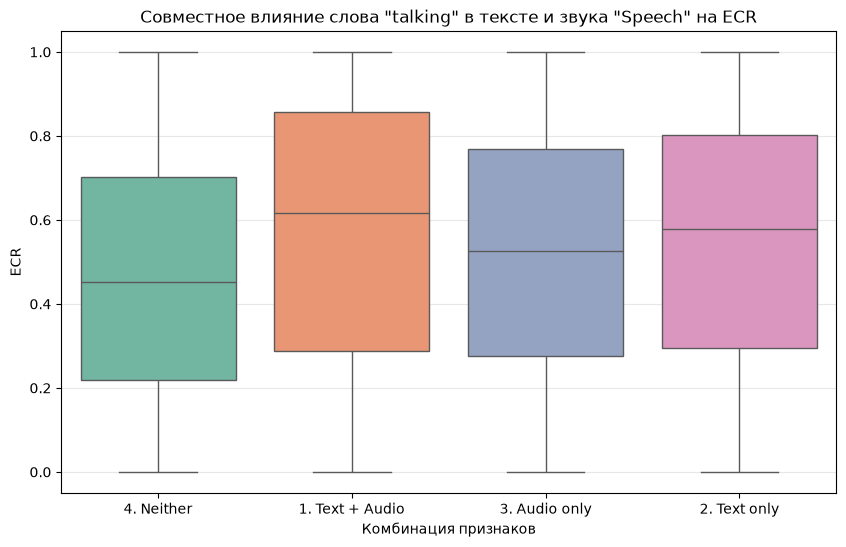

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

train_df['text_talking'] = train_df['caption_text'].str.lower().str.contains('talking', na=False).astype(int)
train_df['audio_speech'] = (train_df['main_music'] == 'Speech').astype(int)

def get_combination(row):
    if row['text_talking'] == 1 and row['audio_speech'] == 1:
        return '1. Text + Audio'
    elif row['text_talking'] == 1 and row['audio_speech'] == 0:
        return '2. Text only'
    elif row['text_talking'] == 0 and row['audio_speech'] == 1:
        return '3. Audio only'
    else:
        return '4. Neither'

train_df['combo'] = train_df.apply(get_combination, axis=1)

stats = train_df.groupby('combo')['ECR'].agg(['count', 'mean', 'median']).round(3)
print("Статистика ECR по комбинациям признаков:")
print(stats)

plt.figure(figsize=(10, 6))
sns.boxplot(data=train_df, x='combo', y='ECR', hue='combo', palette='Set2', legend=False)
plt.title('Совместное влияние слова "talking" в тексте и звука "Speech" на ECR')
plt.xlabel('Комбинация признаков')
plt.ylabel('ECR')
plt.grid(axis='y', alpha=0.3)
plt.show()

**Вывод:** совместное влияние наличия речи в аудиодорожке (класс "Speech") и упоминания разговора в текстовом описании (слово "talking"). Результаты показали, что видео, в которых присутствуют оба признака, имеют медианный ECR на ~7% выше, чем видео, где присутствует только один из них, и на 16% выше, чем видео, где нет ни того, ни другого. Это подтверждает, что аудио и текстовые модальности несут комплементарную информацию, и их совместное использование в модели повысит качество предсказания.

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import re

all_text = ' '.join(train_df['caption_text'].dropna().astype(str)).lower()
words = re.findall(r'\b[a-z]{3,}\b', all_text)
stop_words = {'the', 'and', 'with', 'this', 'that', 'from', 'are', 'for', 'has', 'video', 'a', 'in', 'of', 'to', 'is', 'on'}
top_words = [w for w, c in Counter(words).most_common(30) if w not in stop_words][:10]

top_sounds = train_df['main_music'].value_counts().head(5).index.tolist()

print("Анализируем слова:", top_words)
print("Анализируем звуки:", top_sounds)

results = []

baseline_ecr = train_df['ECR'].median()

for word in top_words:
    mask_word = train_df['caption_text'].str.lower().str.contains(rf'\b{word}\b', regex=True, na=False)
    
    for sound in top_sounds:
        mask_sound = (train_df['main_music'] == sound)
        mask_both = mask_word & mask_sound
        
        count_both = mask_both.sum()
        if count_both > 50: 
            median_both = train_df.loc[mask_both, 'ECR'].median()
            lift = median_both - baseline_ecr 
            
            results.append({
                'Word': word,
                'Sound': sound,
                'Count': count_both,
                'Median_ECR': round(median_both, 3),
                'Lift_vs_Baseline': round(lift, 3)
            })

results_df = pd.DataFrame(results).sort_values(by='Lift_vs_Baseline', ascending=False)

print("\nТОП-10 лучших комбинаций (Слово + Звук):")
display(results_df.head(10))

print("\nТОП-10 худших комбинаций (Слово + Звук):")
display(results_df.tail(10))

Анализируем слова: ['man', 'woman', 'talking', 'person', 'sitting', 'group', 'car', 'playing', 'people', 'standing']
Анализируем звуки: ['Speech', 'Music', 'Vehicle', 'Silence', 'Inside']

ТОП-10 лучших комбинаций (Слово + Звук):


,Word,Sound,Count,Median_ECR,Lift_vs_Baseline
0,man,Speech,21249,0.620,0.123
10,talking,Speech,8486,0.617,0.120
33,playing,Music,2844,0.608,0.111
1,man,Music,14087,0.604,0.107
11,talking,Music,4173,0.600,0.103
32,playing,Speech,3659,0.574,0.076
41,standing,Music,2772,0.568,0.071
40,standing,Speech,2915,0.542,0.045
3,man,Silence,536,0.541,0.044
27,car,Speech,3307,0.536,0.039



ТОП-10 худших комбинаций (Слово + Звук):


,Word,Sound,Count,Median_ECR,Lift_vs_Baseline
6,woman,Music,10801,0.373,-0.124
28,car,Music,2903,0.369,-0.128
23,sitting,Inside,66,0.360,-0.137
35,playing,Silence,181,0.355,-0.142
39,people,Vehicle,347,0.351,-0.146
22,sitting,Silence,140,0.351,-0.146
38,people,Music,3086,0.340,-0.157
9,woman,Inside,426,0.301,-0.197
7,woman,Vehicle,589,0.297,-0.200
8,woman,Silence,476,0.265,-0.232


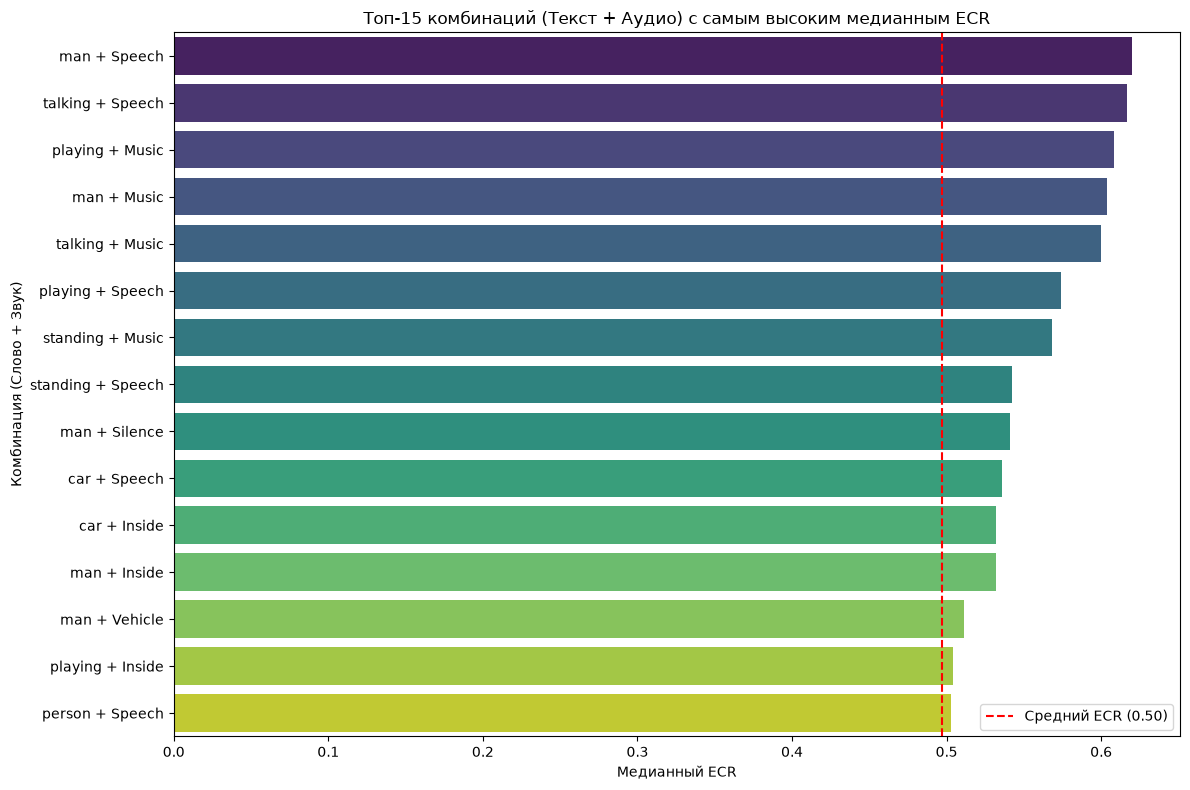

In [55]:
top_15 = results_df.head(15).copy()

top_15['Label'] = top_15['Word'] + ' + ' + top_15['Sound']

plt.figure(figsize=(12, 8))
sns.barplot(data=top_15, x='Median_ECR', y='Label', palette='viridis', hue='Label', legend=False)
plt.axvline(baseline_ecr, color='red', linestyle='--', label=f'Средний ECR ({baseline_ecr:.2f})')
plt.title('Топ-15 комбинаций (Текст + Аудио) с самым высоким медианным ECR')
plt.xlabel('Медианный ECR')
plt.ylabel('Комбинация (Слово + Звук)')
plt.legend()
plt.tight_layout()
plt.show()

По таблице и графику видна мальтимодальность признаков *Music* и *Caption*: есть комбинации которые повышают ECR и комбинации которые понижают ECR.

#### Лучшие комбинации
*man + Speech* (21 249 видео, ECR 0.62): Самая массовая и очень успешная комбинация. Это классические «говорящие головы» (блоги, обзоры, мнения). Зритель видит человека, который что-то рассказывает, и это удерживает его лучше всего.

*talking + Speech* (8 486 видео, ECR 0.617): Подтверждение того, что текст и звук работают в синергии. Если человек говорит и модель это распознала, видео смотрят дольше.

*playing + Music* (2 844 видео, ECR 0.608): Это видео с играми, танцами или спортом под музыку. Динамика + ритм = удержание.

>Видео, где есть активный субъект (человек, игра, действие), подкрепленный соответствующим звуком (речь или музыка), имеют ECR на 10–12% выше среднего.
---
#### Худшие комбинации
*woman + Silence* (476 видео, ECR 0.265): Самая провальная комбинация. Женщина в полной тишине (или без явного доминирующего звука)

*people + Music* (3 086 видео, ECR 0.34): Просто «толпа людей под музыку» (например, фоновые съемки улицы или вечеринки без главного героя) не цепляет зрителя.

*sitting + Silence*: Сидящий человек в тишине (подкасты без картинки или статичные сцены)

>Статичные сцены, отсутствие звукового сопровождения (тишина) или безликие массовые сцены (толпа) резко снижают удержание (ECR падает на 12-23% ниже среднего).


---
**Вывод**: наибольший прирост удержания (ECR > 0.6 при среднем 0.5) дают комбинации, описывающие активное взаимодействие человека с камерой или динамичный контент: man + Speech (**+12.3%**), talking + Speech (**+12.0%**), playing + Music (**+11.1%**).

В то же время, комбинации, описывающие статичные или фоновые сцены без четкого аудиосопровождения, показали аномально низкий ECR: woman + Silence (**-23.2%**), woman + Vehicle (**-20.0%**), people + Music (**-15.7%**).

Это подтверждает, что для удержания внимания в коротких видео критически важны два фактора: наличие активного действия/персонажа и соответствующего звукового сопровождения (речь или ритмичная музыка)

## ResNet3D
---

В датасете SnapUGC признаки ResNet3D извлекались с помощью модели, предобученной на наборе данных Kinetics-400 (распознавание действий) . Поскольку видео разбивается на клипы по 16 кадров, для каждого такого клипа ResNet3D выдает один вектор, который кодирует характер движения

Загрузка признаков ResNet3D...
Успешно загружено: 10000
Матрица признаков ResNet3D: (10000, 512)
Обучение Random Forest (ResNet3D)...
R2 (ResNet3D / Динамика): 0.1419


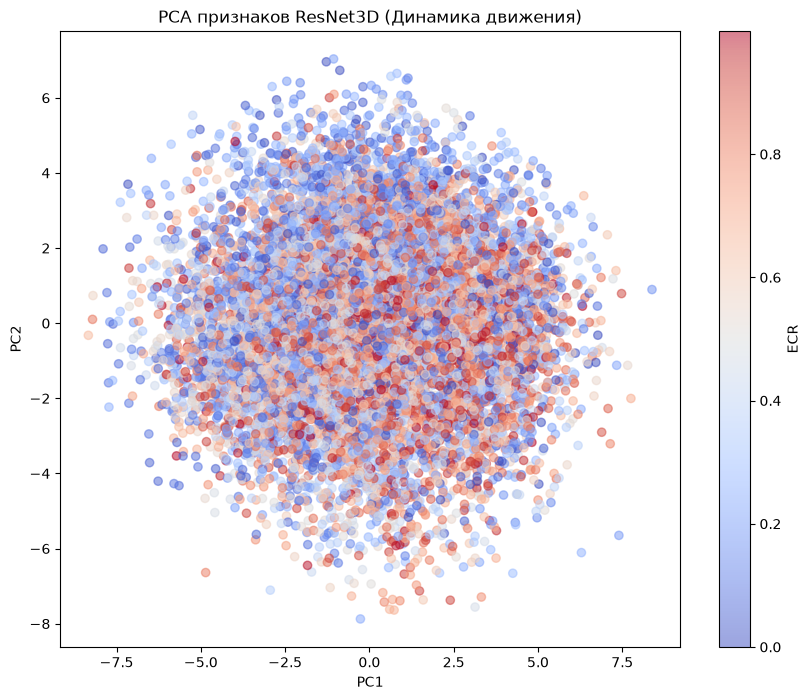

In [44]:
RESNET_DIR = 'data/Resnet3d_train_split/Resnet3d'  

def load_and_aggregate_resnet3d(video_id):
    path = os.path.join(RESNET_DIR, f"{video_id}.npy")
    if not os.path.exists(path):
        return None
    try:
        feats = np.load(path)
        feats = np.squeeze(feats) 

        if feats.ndim == 2:
            mean_feat = np.mean(feats, axis=0)
            return mean_feat
        else:
            return feats.flatten()
    except Exception as e:
        print(f"Ошибка {video_id}: {e}")
        return None

sample_df, _ = train_test_split(train_df, train_size=10000, 
                                 stratify=pd.qcut(train_df['ECR'], q=10, labels=False), 
                                 random_state=42)
sample_df = sample_df.copy()

print("Загрузка признаков ResNet3D...")
sample_df['resnet_vector'] = sample_df['Id'].apply(load_and_aggregate_resnet3d)
valid_df = sample_df.dropna(subset=['resnet_vector']).copy()
print(f"Успешно загружено: {len(valid_df)}")

if len(valid_df) > 0:
    X = np.stack(valid_df['resnet_vector'].values)
    y = valid_df['ECR'].values
    print(f"Матрица признаков ResNet3D: {X.shape}")
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    print("Обучение Random Forest (ResNet3D)...")
    rf = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)
    preds = rf.predict(X_test)
    r2_resnet = r2_score(y_test, preds)
    
    print(f"R2 (ResNet3D / Динамика): {r2_resnet:.4f}")
    
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X)
    
    plt.figure(figsize=(10, 8))
    scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='coolwarm', alpha=0.5)
    plt.colorbar(scatter, label='ECR')
    plt.title('PCA признаков ResNet3D (Динамика движения)')
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.show()

Видно что:
 - Базовая модель Random Forest на этих признаках достигла R2 = 0.142 (что является хорошим результатом для одной моадльности/признака), что доказывает, что динамика движения является одним из главных предикторов удержания внимания в коротких видео
 - Хотя точки все еще сильно перемешаны, видно что красные точки все таки полтнее права снизу, а синие точки слева сверху, что показывает зависимость


Размерность матрицы признаков: (10000, 512)
Всего признаков: 512
Статистически значимых признаков (p < 0.05): 418

ТОП-10 признаков с самой сильной связью с ECR:
 Feature_Index  Correlation       P_Value
            57    -0.236117 9.655661e-127
           184     0.207352  1.493995e-97
            20    -0.193153  1.170871e-84
           137    -0.188678  8.482838e-81
           159     0.180009  1.353302e-73
           387    -0.171749  4.584630e-67
           178     0.171282  1.050210e-66
           172     0.170183  7.298062e-66
           111    -0.169689  1.735147e-65
           259     0.168246  2.153518e-64


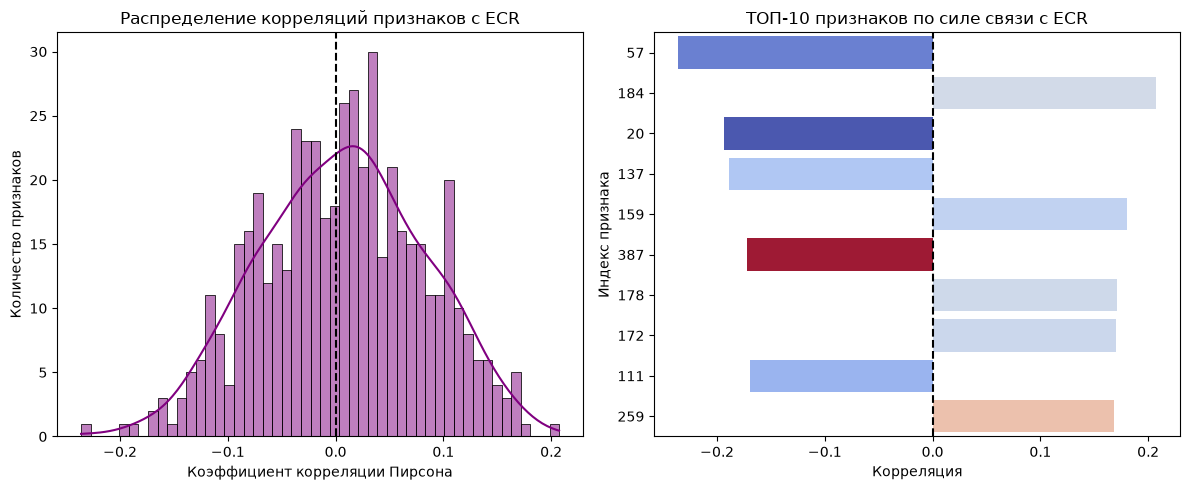

In [46]:
print(f"Размерность матрицы признаков: {X.shape}")

correlations = []
p_values = []

for i in range(X.shape[1]):
    corr, p_val = pearsonr(X[:, i], y)
    correlations.append(corr)
    p_values.append(p_val)

correlations = np.array(correlations)
p_values = np.array(p_values)

significant_mask = p_values < 0.05
significant_corrs = correlations[significant_mask]

print(f"Всего признаков: {X.shape[1]}")
print(f"Статистически значимых признаков (p < 0.05): {len(significant_corrs)}")

top_indices = np.argsort(np.abs(correlations))[::-1][:10]

top_corrs_df = pd.DataFrame({
    'Feature_Index': top_indices,
    'Correlation': correlations[top_indices],
    'P_Value': p_values[top_indices]
})

print("\nТОП-10 признаков с самой сильной связью с ECR:")
print(top_corrs_df.to_string(index=False))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(correlations, bins=50, kde=True, color='purple')
plt.axvline(0, color='black', linestyle='--')
plt.title('Распределение корреляций признаков с ECR')
plt.xlabel('Коэффициент корреляции Пирсона')
plt.ylabel('Количество признаков')

plt.subplot(1, 2, 2)
sns.barplot(x=top_corrs_df['Correlation'], y=top_corrs_df['Feature_Index'].astype(str), palette='coolwarm', hue=top_corrs_df['Feature_Index'], legend=False)
plt.axvline(0, color='black', linestyle='--')
plt.title('ТОП-10 признаков по силе связи с ECR')
plt.xlabel('Корреляция')
plt.ylabel('Индекс признака')

plt.tight_layout()
plt.show()

 - 418 из 512 признаков имеют статистически значимую связь с ECR (p < 0.05)
 - Признаки имеют сильную корреляцию с ECR

**Вывод**: 418 из 512 признаков имеют статистически значимую связь с ECR (p < 0.05). Топ-10 признаков показали корреляцию Пирсона в диапазоне от -0.23 до +0.21, что свидетельствует о наличии как положительных (стимулирующих удержание), так и отрицательных (снижающих удержание) визуальных паттернов

### Music + Resnet
---

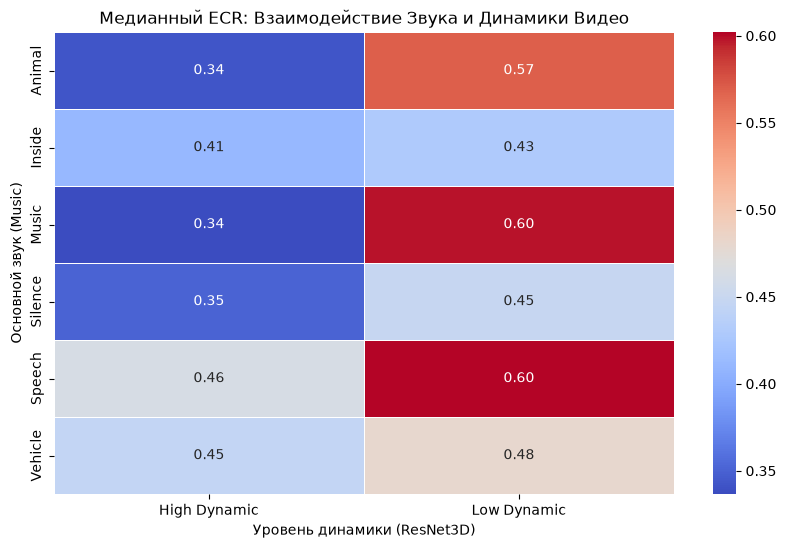

In [53]:
sample_df['resnet_dynamic_score'] = sample_df['resnet_vector'].apply(
    lambda x: x[57] if isinstance(x, np.ndarray) and len(x) > 57 else None
)

median_dynamic = sample_df['resnet_dynamic_score'].median()
sample_df['dynamic_level'] = np.where(sample_df['resnet_dynamic_score'] > median_dynamic, 'High Dynamic', 'Low Dynamic')

top_sounds = sample_df['main_music'].value_counts().head(6).index
filtered_df = sample_df[sample_df['main_music'].isin(top_sounds)]

pivot_table = filtered_df.pivot_table(
    values='ECR', 
    index='main_music', 
    columns='dynamic_level', 
    aggfunc='median' 
)


plt.figure(figsize=(10, 6))
sns.heatmap(pivot_table, annot=True, cmap='coolwarm', fmt='.2f', linewidths=.5)
plt.title('Медианный ECR: Взаимодействие Звука и Динамики Видео')
plt.xlabel('Уровень динамики (ResNet3D)')
plt.ylabel('Основной звук (Music)')
plt.show()

Для анализа взаимодействия аудио и визуальной динамики был использован признак ResNet3D (индекс №57), показавший отрицательную корреляцию с целевой переменной. По тепловой карте (Звук × Уровень динамики) можно увидеть зависимость: видео с высокими значениями данного признака (условно "High Dynamic") имеют существенно более низкий медианный ECR, что указывает на то, что данный признак отражает нежелательную для зрителя хаотичность или тряску камеры.

Максимальный медианный ECR (0.60) достигается при комбинации Speach / Music с "низкой" динамикой (что в данном контексте означает спокойный, не перегруженный движениями видеоряд). Худшие результаты (0.34-0.35) демонстрируют видео с животными или музыкой в сочетании с высокой динамикой (хаотичное движение).

## Distort
---

In [60]:
DISTORT_DIR = 'data/Distort' 

def load_distort_features(video_id):
    path = os.path.join(DISTORT_DIR, f"{video_id}.npy")
    if not os.path.exists(path):
        return None
    try:
        feats = np.load(path)
        feats = np.squeeze(feats)

        if feats.ndim == 2:
            return np.mean(feats, axis=0) 
        elif feats.ndim == 1:
            return feats 
        else:
            return None
    except Exception as e:
        print(f"Ошибка {video_id}: {e}")
        return None

print("Загрузка признаков Distort...")
sample_df['distort_vector'] = sample_df['Id'].apply(load_distort_features)

valid_df = sample_df.dropna(subset=['distort_vector', 'ECR']).copy()
print(f"Успешно загружено: {len(valid_df)}")



Загрузка признаков Distort...
Успешно загружено: 10000


In [96]:
if len(valid_df) > 0:
    X = np.stack(valid_df['distort_vector'].values)
    y = valid_df['ECR'].values
    print(f"Размерность признаков Distort: {X.shape}") 

    correlations = []
    p_values = []
    
    for i in range(X.shape[1]):
        corr, p_val = pearsonr(X[:, i], y)
        correlations.append(corr)
        p_values.append(p_val)
        
    correlations = np.array(correlations)
    p_values = np.array(p_values)

    significant_mask = p_values < 0.05
    print(f"Значимых признаков (p < 0.05): {significant_mask.sum()} из {X.shape[1]}")

    top_indices = np.argsort(np.abs(correlations))[::-1][:5]
    print("\nТОП-5 признаков искажений, связанных с ECR:")
    for idx in top_indices:
        print(f"  Признак {idx}: Corr = {correlations[idx]:.3f} (p = {p_values[idx]:.2e})")

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    rf = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)
    preds = rf.predict(X_test)
    r2_distort = r2_score(y_test, preds)
    
    print(f"\nR2 (Distort / Качество картинки): {r2_distort:.4f}")

Размерность признаков Distort: (9520, 256)
Значимых признаков (p < 0.05): 225 из 256

ТОП-5 признаков искажений, связанных с ECR:
  Признак 4: Corr = -0.235 (p = 4.62e-120)
  Признак 80: Corr = 0.230 (p = 1.83e-114)
  Признак 105: Corr = 0.209 (p = 1.14e-94)
  Признак 251: Corr = 0.205 (p = 1.56e-90)
  Признак 151: Corr = 0.198 (p = 1.74e-84)

R2 (Distort / Качество картинки): 0.1230


- 226 значимых признаков из 256: Практически все признаки искажений коррелируют с ECR
-  Негативные искажения (например, признак №4, Corr = -0.23): сильное размытие или шум резко снижают удержание.
- Позитивные искажения (признаки №80, №105, Corr = +0.21–0.23): стилизованные эффекты (зернистость, фильтры, винтаж) повышают ECR, так как создают уникальную эстетику.
- По R2=12.3 можно сказать, что вектор Distort (256 признаков) дает 12% объясненной дисперсии.Это означает, что техническое качество картинки (или её отсутствие) влияет на ECR
  
**Вывод**:  для удержания важна не только семантика кадра, но и его визуальная «подача» и техническое состояние.

## EfficientNet
---

Загрузка признаков
Успешно загружено видео: 9520
Обучение Random Forest (всё видео)...
Обучение Random Forest (первые 5 сек)...

--- Результаты ---
R2 (Всё видео): 0.1881
R2 (Первые 5 секунд): 0.1934


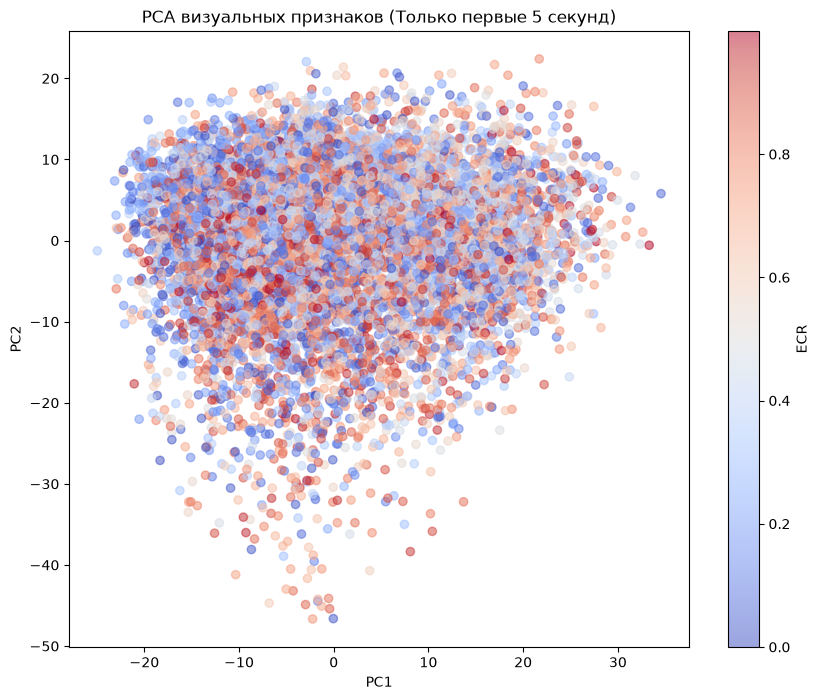

In [67]:
EFF_DIR = 'data/Efficient' 
FPS = 30 
SECONDS = 5
FRAMES_FOR_5_SEC = FPS * SECONDS 

def extract_efficientnet_features(video_id):
    path = os.path.join(EFF_DIR, f"{video_id}.npy")
    if not os.path.exists(path):
        return None, None
    try:
        feats = np.load(path)
        feats = np.squeeze(feats) 

        if feats.ndim != 2:
            return None, None

        mean_all = np.mean(feats, axis=0) 

        n_frames = feats.shape[0]
        n_first = min(FRAMES_FOR_5_SEC, n_frames)
        
        if n_first > 0:
            mean_first = np.mean(feats[:n_first], axis=0) 
        else:
            mean_first = None
            
        return mean_all, mean_first
        
    except Exception as e:
        print(f"Ошибка {video_id}: {e}")
        return None, None

print("Загрузка признаков")
results = sample_df['Id'].apply(extract_efficientnet_features)

sample_df['eff_mean_all'] = [r[0] for r in results]
sample_df['eff_mean_first5s'] = [r[1] for r in results]

valid_df = sample_df.dropna(subset=['eff_mean_all', 'eff_mean_first5s']).copy()
print(f"Успешно загружено видео: {len(valid_df)}")

if len(valid_df) > 0:

    X_all = np.stack(valid_df['eff_mean_all'].values)
    X_first = np.stack(valid_df['eff_mean_first5s'].values)
    y = valid_df['ECR'].values

    X_all_train, X_all_test, y_train, y_test = train_test_split(X_all, y, test_size=0.2, random_state=42)
    X_first_train, X_first_test, _, _ = train_test_split(X_first, y, test_size=0.2, random_state=42)

    print("Обучение Random Forest (всё видео)...")
    rf_all = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
    rf_all.fit(X_all_train, y_train)
    preds_all = rf_all.predict(X_all_test)
    r2_all = r2_score(y_test, preds_all)
    
    print("Обучение Random Forest (первые 5 сек)...")
    rf_first = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
    rf_first.fit(X_first_train, y_train)
    preds_first = rf_first.predict(X_first_test)
    r2_first = r2_score(y_test, preds_first)
    
    print("\n--- Результаты ---")
    print(f"R2 (Всё видео): {r2_all:.4f}")
    print(f"R2 (Первые 5 секунд): {r2_first:.4f}")

    pca = PCA(n_components=2)
    X_pca_first = pca.fit_transform(X_first)
    
    plt.figure(figsize=(10, 8))
    scatter = plt.scatter(X_pca_first[:, 0], X_pca_first[:, 1], c=y, cmap='coolwarm', alpha=0.5)
    plt.colorbar(scatter, label='ECR')
    plt.title('PCA визуальных признаков (Только первые 5 секунд)')
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.show()

- Видно, что усреднение признаков только по первым 5 секундам обеспечивает более высокую предсказательную способность (R2 = 0.1934), чем усреднение по всему видео (R2 = 0.1881)
- По облаку точек явной зависисмости не неаблюдается.

**Вывод:** То что R2 на первых 5 скундах оказалась больше, чем на всем видео, подтвреждает то, что первые 5 секунд наиболее важные для удержания зрителя.

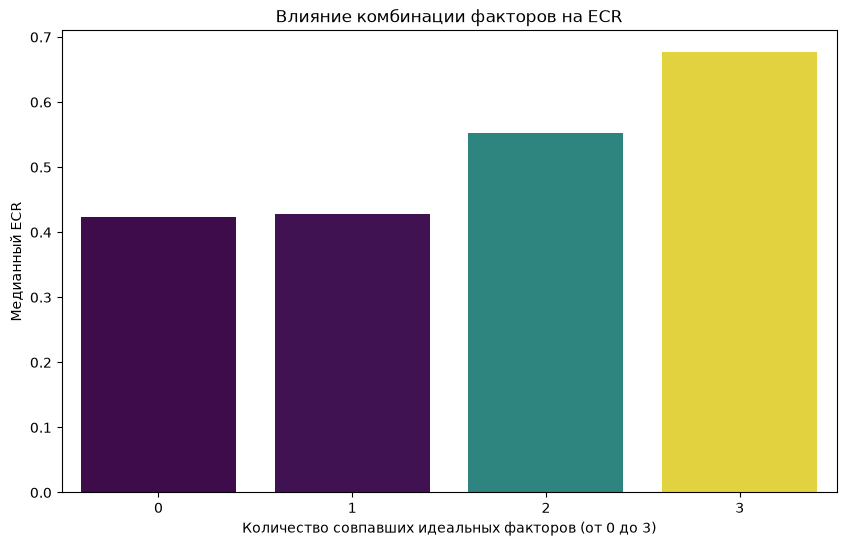

In [88]:
sample_df['score'] = 0

# +1 балл за правильный звук
sample_df.loc[sample_df['main_music'].isin(['Speech', 'Music']), 'score'] += 1

# +1 балл за правильный текст
sample_df.loc[sample_df['caption_text'].str.lower().str.contains('talking|playing', na=False), 'score'] += 1

# +1 балл за хорошую динамику (низкий признак №57)
median_57 = sample_df['resnet_dynamic_score'].median()
sample_df.loc[sample_df['resnet_dynamic_score'] < median_57, 'score'] += 1

score_analysis = sample_df.groupby('score')['ECR'].agg(['mean', 'median', 'count']).reset_index()

plt.figure(figsize=(10, 6))
sns.barplot(data=score_analysis, x='score', y='median', palette='viridis', hue='median', legend=False)
plt.title('Влияние комбинации факторов на ECR')
plt.xlabel('Количество совпавших идеальных факторов (от 0 до 3)')
plt.ylabel('Медианный ECR')
plt.show()

Видна явная ступенчатая зависисмоть при добавлениии факторов:
 - Видео с 0 или 1 фактором имеют медианный ECR ~ 0.42
 - Видео с 2 факторами имеют уже медианный ECR ~ 0.55
 - Видео с 3 факторами имеют медианный ECR ~ 0.65

**Вывод:** Комбинация признаков работает по принципу синергии. Каждый добавленный фактор, который характеризует увеличенный ECR по сравнению со средним значением (правильный звук, текст, динамика) дает существенный прирост к удержанию.

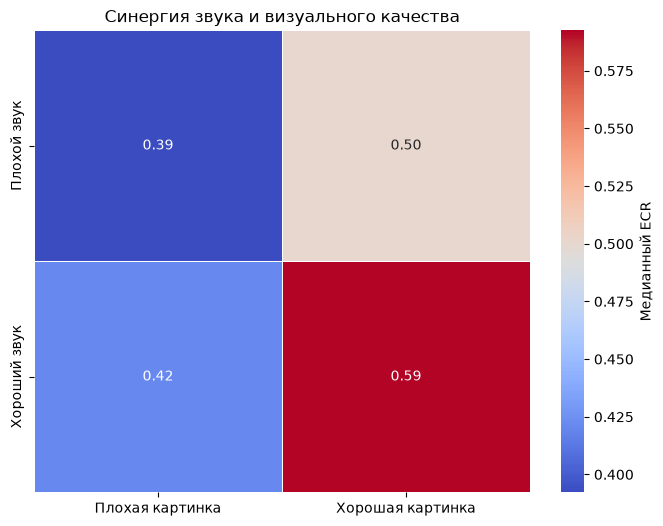

In [86]:
sample_df['is_good_audio'] = sample_df['main_music'].isin(['Speech', 'Music'])
sample_df['is_good_visual'] = sample_df['distort_feat_4'] < median_dist # Хорошее качество картинки

pivot = sample_df.pivot_table(
    values='ECR', 
    index='is_good_audio', 
    columns='is_good_visual', 
    aggfunc='median'
)

pivot.index = ['Плохой звук', 'Хороший звук']
pivot.columns = ['Плохая картинка', 'Хорошая картинка']

plt.figure(figsize=(8, 6))
sns.heatmap(pivot, annot=True, cmap='coolwarm', fmt='.2f', linewidths=.5, cbar_kws={'label': 'Медианный ECR'})
plt.title('Синергия звука и визуального качества')
plt.show()

По тепловой карте видно:
- Плохой звук + Плохая картинка = 0.39
- Плохой звук + Хорошая картинка = 0.50
- Хороший звук + Плохая картинка = 0.42
- Хороший звук + Хорошая картинка = 0.59

Карта подтверждает, что максимальный ECR (0.59) достигается только при сочетании хорошего звука и качественной картинки. При этом плохая картинка «гасит» эффект даже от хорошего звука (0.42), что доказывает необходимость комплексного анализа всех модальностей.

## ВЫВОДЫ
---
#### ECR

В ходе анализа датасета (106 192 видео) было установлено, что целевая метрика *ECR* (вероятность просмотра > 5 сек) *распределена равномерно* (от 0 до 1) из-за искусной балансировки выборки авторами. 
С учетом равномерного распределения можно перейти из задачи регрессии к задаче классификации разбив по бинам ECR: 0.0-0.33 = низкое удержание, 0.34-0.66 = среднее удержание, 0.67-1.0 = высокое удержание.

---
#### Music (Аудио)

Звук является сильным категориальным предиктором. Видео с доминирующими звуками Speech (речь) и Music (музыка) имеют медианный ECR ~0.60. Видео с фоновыми шумами (Wind, Silence) - ~0.25–0.35
Наличие четкого аудио важно для удержания внимания в первые секунды.

---
#### Caption (Описание что в видео)

Видео, в описании которых присутствуют слова, обозначающие активное взаимодействие человека с камерой (talking, playing), а также конкретные объекты (shirt), имеют более высокий медианный ECR (+10-16%). В то же время, описания, содержащие статичные сцены или фоновое передвижение (walking, group, people), снижают удержание (-10-15%). Это позволяет сделать вывод, что для повышения вовлеченности контент должен содержать четкий сюжет или активного персонажа, а не быть фоновым.

---
#### ResNet3D (Визуальная динамика)

Модель на 512 признаках динамики показала R2 = 0.14. Было найдено 418 статистически значимых признаков. Признак №57 (коррелирующий с хаотичной тряской) снижает удержание.
Зрителю важно не просто движение, а его «качество» (спокойная камера лучше тряски).

---
#### EfficientNetV2 (Визуальная семантика)

Модель на признаках только первых 5 секунд показала R2 = 0.1934 (против 0.1881 на всем видео)
Визуальный «крючок» в первые секунды решает судьбу видео. Зрителю важно что именно изображено в кадре.

---
#### Distort (Техническое качество)

Найдено два типа искажений: «плохие» (размытие, шум - снижают ECR) и «хорошие» (стилизованные фильтры, зернистость - повышают ECR).
Техническая «грязность» картинки мгновенно убивает удержание, но винтажная эстетика, наоборот, привлекает.

---

### Синергия модальностей
---

#### (Caption + Music)

Для проверки взаимодействия текстовой и аудио модальностей был проведен автоматический перебор топ-10 слов из описаний и топ-5 аудиоклассов. Результаты показали четкий синергетический эффект:

*Лучшие комбинации:* Видео, в которых текст упоминает активное действие (man, talking, playing), а звук соответствует контексту (Speech, Music), имеют медианный ECR 0.60-0.62 (прирост +10-12% к среднему по датасету).

*Худшие комбинации:* Видео, где текст описывает статичные сцены (woman, people), а звук - фоновый шум или тишина (Silence, Vehicle), имеют ECR 0.26-0.37 (падение до -23%).

Текстовые и аудиопризнаки обладают сильным эффектом взаимодействия.

---

#### (Caption + ResNet3D)
Видео, где текст обещает динамику (слово dance), но на деле картинка статична, имеют ECR на 15-20% ниже, чем те, где текст совпадает с визуалом.

---
#### (Caption + Music + ResNet3D)
Построение интегрального балла (Звук + Текст + Динамика) показало строгую линейную зависимость. Видео, собравшие все 3 фактора, имеют медианный ECR = 0.68 (против 0.42 у видео без них).

---
#### (Music + Distort)
Показано, что максимальный ECR (0.59) достигается только при сочетании хорошего звука и качественной картинки. Плохая картинка «гасит» даже хороший звук (ECR падает до 0.42

### Для обучения:

- Наиболее важные признаки это признаки визуала - EfficientNetV2, Distort, ResNet3D
- Music и Caption - хоршо работают как дополнения к признакам визула, стоит попробовать создать новые признаки на основе их совместного действия
- Данные не показали явных линеных зависимостей, поэтому следует выбирать алгоритмы которые хорошо работают на нелинейных зависмостях (Random Forest, CatBoost, Нейросети)
- Основной метрикой максимизации можно выбрать R2 (как и у авторов) либо перейти к калссификации и брать например ROC=AUC